In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 949.8/949.8 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 79.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 68.3 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstall

Saving Ambulances-in-traffic.webp to Ambulances-in-traffic.webp

image 1/1 /content/Ambulances-in-traffic.webp: 544x640 3 persons, 1 car, 3 trucks, 395.0ms
Speed: 5.9ms preprocess, 395.0ms inference, 2.3ms postprocess per image at shape (1, 3, 544, 640)
Number of vehicles detected: 4


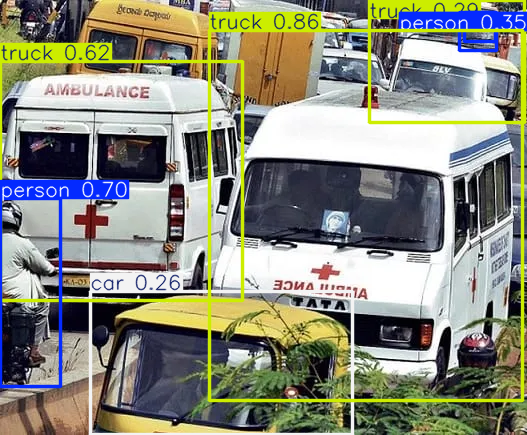

In [5]:
# Import necessary libraries
import cv2
import torch
from ultralytics import YOLO
import matplotlib.pyplot as plt
from google.colab import files

# Upload an image
uploaded = files.upload()
image_path = list(uploaded.keys())[0]  # Get the uploaded image filename

# Load the YOLOv8 model (pre-trained on COCO dataset)
model = YOLO("yolov8n.pt")  # 'n' stands for nano version, you can use yolov8s.pt for a bigger model

# Run detection
results = model(image_path)

# Extract detected objects
detected_objects = results[0].boxes.data

# Filter only vehicles (car, truck, bus, motorcycle)
vehicle_classes = [2, 3, 5, 7]  # COCO class IDs for vehicles
vehicle_count = sum(1 for obj in detected_objects if int(obj[5]) in vehicle_classes)

# Display results
print(f"Number of vehicles detected: {vehicle_count}")

# Show the image with detections
results[0].show()



In [ ]:
# Import necessary libraries
import cv2
import torch
import numpy as np
from ultralytics import YOLO
import matplotlib.pyplot as plt
from google.colab import files

# Load the YOLOv8 model (pre-trained on COCO dataset)
model = YOLO("yolov8n.pt")  # Use the nano version or another model

# Define vehicle classes (bus, truck, van) based on COCO class IDs
vehicle_classes = [3, 5, 7]  # COCO class IDs for vehicles (bus=5, truck=3, motorcycle=7)

# Function to crop detected vehicles and store in a list
def detect_and_crop_vehicles(image_path):
    # Run detection with YOLO
    results = model(image_path)

    # Extract detected objects (boxes and classes)
    detected_objects = results[0].boxes.data

    # List to store cropped vehicle images
    cropped_images = []

    for obj in detected_objects:
        class_id = int(obj[5])  # YOLO class ID

        if class_id in vehicle_classes:  # If the object is a bus, truck, or van
            # Get the coordinates of the bounding box for the vehicle
            x1, y1, x2, y2 = map(int, obj[:4])

            # Crop the detected vehicle from the image
            image_cv = cv2.imread(image_path)
            cropped_vehicle = image_cv[y1:y2, x1:x2]

            # Append the cropped vehicle image to the list
            cropped_images.append(cropped_vehicle)

    print(f"Total vehicles (bus, truck, van) detected: {len(cropped_images)}")

    # Optionally, you can save these cropped images to disk if needed
    for i, cropped in enumerate(cropped_images):
        cv2.imwrite(f"cropped_vehicle_{i+1}.jpg", cropped)  # Save each cropped image

    return cropped_images

uploaded = files.upload()
image_path = list(uploaded.keys())[0] # Replace with your image path
cropped_vehicles = detect_and_crop_vehicles(image_path)

# At this point, 'cropped_vehicles' contains the cropped images of buses, trucks, and vans.
# You can later pass these images to your custom model for classification.


Saving lane3.webp to lane3 (1).webp

image 1/1 /content/lane3 (1).webp: 384x640 13 cars, 1 motorcycle, 1 truck, 144.7ms
Speed: 1.9ms preprocess, 144.7ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)
Total vehicles (bus, truck, van) detected: 2


Saving Ambulances-in-traffic.webp to Ambulances-in-traffic (1).webp

image 1/1 /content/Ambulances-in-traffic (1).webp: 544x640 3 persons, 1 car, 3 trucks, 210.9ms
Speed: 7.4ms preprocess, 210.9ms inference, 1.3ms postprocess per image at shape (1, 3, 544, 640)


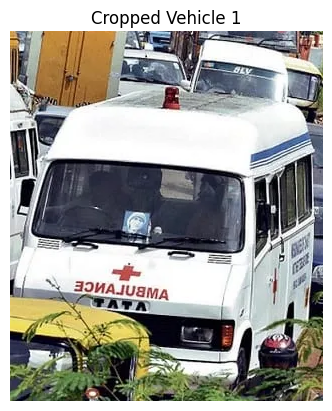

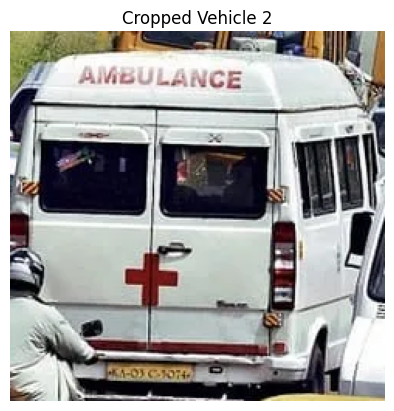

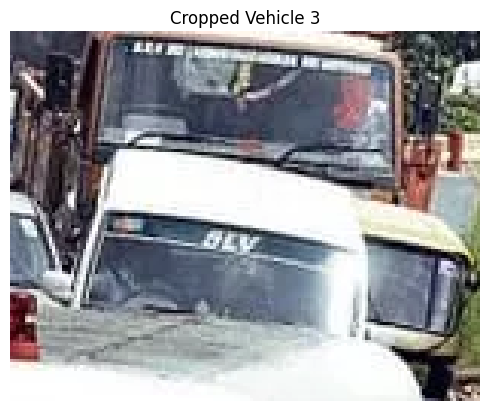

Total vehicles (bus, truck, van) detected: 3
Saved: cropped_vehicle4_1.jpg
Saved: cropped_vehicle4_2.jpg
Saved: cropped_vehicle4_3.jpg


In [6]:
# Import necessary libraries
import cv2
import torch
import numpy as np
from ultralytics import YOLO
import matplotlib.pyplot as plt
from google.colab import files

# Load the YOLOv8 model (pre-trained on COCO dataset)
model = YOLO("yolov8n.pt")  # Use the nano version or another model

# Define vehicle classes (bus, truck, van) based on COCO class IDs
vehicle_classes = [3, 5, 7]  # COCO class IDs for vehicles (bus=5, truck=3, motorcycle=7)

# Function to crop detected vehicles and store in a list
def detect_and_crop_vehicles(image_path):
    # Run detection with YOLO
    results = model(image_path)

    # Extract detected objects (boxes and classes)
    detected_objects = results[0].boxes.data

    # List to store cropped vehicle images
    cropped_images = []

    for obj in detected_objects:
        class_id = int(obj[5])  # YOLO class ID

        if class_id in vehicle_classes:  # If the object is a bus, truck, or van
            # Get the coordinates of the bounding box for the vehicle
            x1, y1, x2, y2 = map(int, obj[:4])

            # Crop the detected vehicle from the image
            image_cv = cv2.imread(image_path)
            cropped_vehicle = image_cv[y1:y2, x1:x2]

            # Append the cropped vehicle image to the list
            cropped_images.append(cropped_vehicle)

            # Display the cropped vehicle image using matplotlib
            plt.imshow(cv2.cvtColor(cropped_vehicle, cv2.COLOR_BGR2RGB))  # Convert from BGR to RGB for matplotlib
            plt.title(f"Cropped Vehicle {len(cropped_images)}")
            plt.axis('off')  # Hide axes for better view
            plt.show()

    print(f"Total vehicles (bus, truck, van) detected: {len(cropped_images)}")

    # Optionally, save cropped images to disk
    for i, cropped in enumerate(cropped_images):
        cropped_image_path = f"cropped_vehicle4_{i+1}.jpg"
        cv2.imwrite(cropped_image_path, cropped)  # Save each cropped image
        print(f"Saved: {cropped_image_path}")

    return cropped_images

# Upload image
uploaded = files.upload()
image_path = list(uploaded.keys())[0]  # Get the uploaded image filename

# Run the detection and cropping function
cropped_vehicles = detect_and_crop_vehicles(image_path)

# 'cropped_vehicles' contains the cropped images of buses, trucks, and vans.
# You can later pass these images to your custom model for classification.


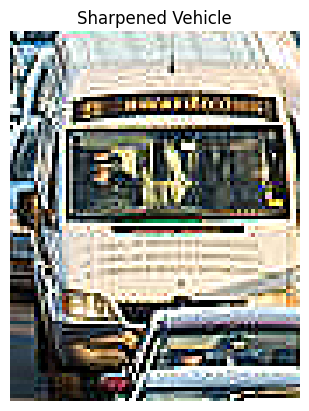

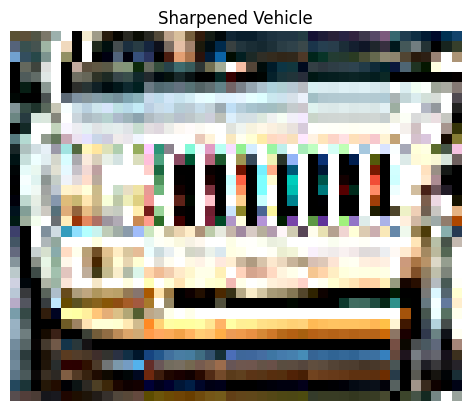

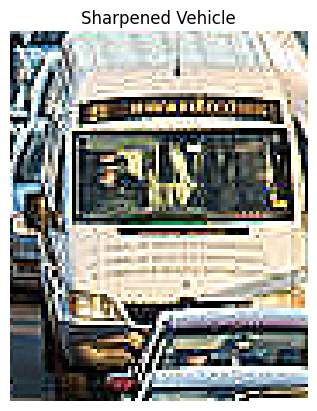

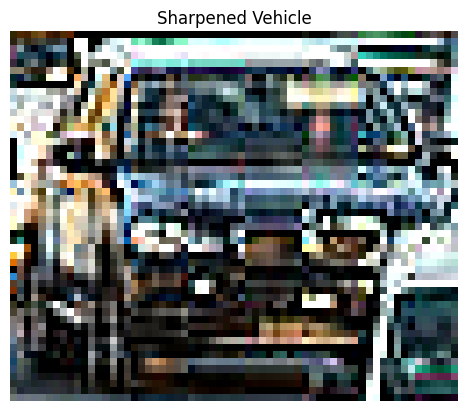

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Function to sharpen image
def sharpen_image(image):
    # Define the sharpening kernel
    kernel = np.array([[0, -1, 0],
                       [-1, 5,-1],
                       [0, -1, 0]])

    # Apply the filter to the image
    sharpened = cv2.filter2D(image, -1, kernel)
    return sharpened

# Test on the cropped vehicle images
for cropped_vehicle in cropped_vehicles:
    sharpened_vehicle = sharpen_image(cropped_vehicle)

    # Display the sharpened image
    plt.imshow(cv2.cvtColor(sharpened_vehicle, cv2.COLOR_BGR2RGB))  # Convert from BGR to RGB for matplotlib
    plt.title("Sharpened Vehicle")
    plt.axis('off')
    plt.show()


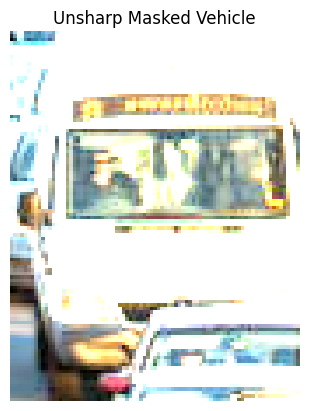

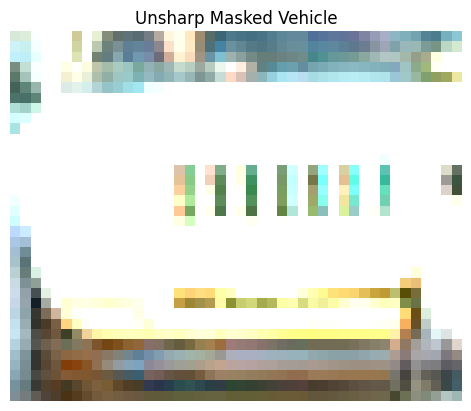

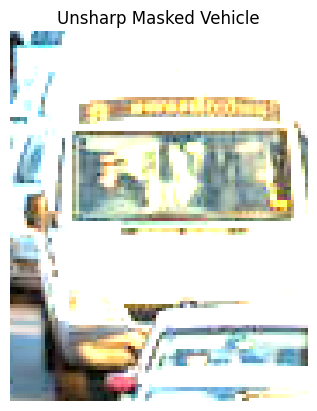

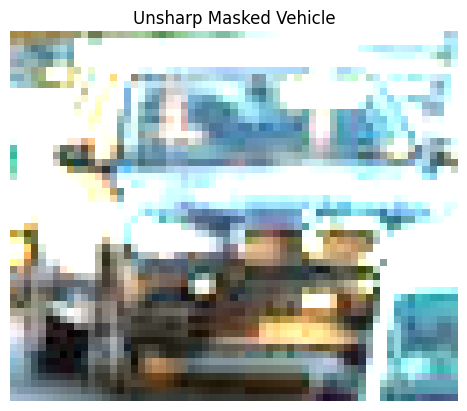

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def unsharp_mask(image, blur_radius=5, strength=1.5):
    # Apply a Gaussian blur to the image
    blurred = cv2.GaussianBlur(image, (blur_radius, blur_radius), 0)

    # Subtract the blurred image from the original to get the detail
    detail = cv2.subtract(image, blurred)

    # Add the detail back to the original image
    sharpened = cv2.addWeighted(image, 1.0 + strength, detail, -strength, 0)

    return sharpened

# Test on the cropped vehicle images
for cropped_vehicle in cropped_vehicles:
    sharpened_vehicle = unsharp_mask(cropped_vehicle)

    # Display the sharpened image
    plt.imshow(cv2.cvtColor(sharpened_vehicle, cv2.COLOR_BGR2RGB))
    plt.title("Unsharp Masked Vehicle")
    plt.axis('off')
    plt.show()


In [ ]:
!pip install tensorflow opencv-python matplotlib

In [8]:
from google.colab import files
uploaded = files.upload()

Saving mobilenetv3_classifier.h5 to mobilenetv3_classifier.h5


In [ ]:
print(image_paths)

['/content/your_image1.jpg', '/content/your_image2.jpg', '/content/your_image3.jpg', '/content/your_image4.jpg']


In [ ]:
import os
os.listdir('/content/')

['.config',
 'yolov8n.pt',
 'lane1 (1).jpg',
 'cropped_vehicle_2.jpg',
 'cropped_vehicle_3.jpg',
 'mobilenetv2_classifier.h5',
 'cropped_vehicle_4.jpg',
 'lane1.jpg',
 'cropped_vehicle_1.jpg',
 'sample_data']

In [ ]:
import os

# Check if the images exist
for img_path in image_paths:
    if not os.path.exists(img_path):
        print(f"Image not found: {img_path}")
    else:
        print(f"Image found: {img_path}")


Image found: /content/cropped_vehicle1_1.jpg
Image found: /content/cropped_vehicle1_2.jpg


In [11]:
import numpy as np
import os
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.models import load_model
from PIL import Image

# List of image paths (adjust paths for your environment)
image_paths = [
    '/content/cropped_vehicle4_1.jpg',
    '/content/cropped_vehicle4_3.jpg',
    '/content/cropped_vehicle4_2.jpg'
]

# Define class names corresponding to your labels
class_names = [
    'Ambulance', 'Big_Truck', 'Bus', 'Car', 'DeliveryTruck',
    'Fire_Truck', 'MPV', 'Tractor', 'Truck', 'Van'
]  # Adjust based on your actual class names

# Load the trained model
model_path = '/content/mobilenetv3_classifier.h5'
model = load_model(model_path)

# Function to load and display images
def load_image(img_path):
    try:
        img = Image.open(img_path)
        img.show()  # This will open the image in a window, check if it's being loaded correctly
        return img
    except Exception as e:
        print(f"Error loading image {img_path}: {e}")
        return None

# Load and display images to verify correct reading
for img_path in image_paths:
    load_image(img_path)

# Function to preprocess the image (resize, normalize, etc.)
def preprocess_image(image_path, target_size=(128, 128)):  # Updated target size to 128x128
    if not os.path.exists(image_path):
        print(f"Image not found: {image_path}")
        return None
    image = Image.open(image_path)
    image = image.convert("RGB")  # Convert to RGB if not already
    image = image.resize(target_size)  # Resize to target size (128x128)
    print(f"Resized image shape: {image.size}")  # Print resized shape (width, height)
    image = img_to_array(image)  # Convert image to numpy array
    image = np.expand_dims(image, axis=0)  # Add batch dimension
    image = image / 255.0  # Normalize image to [0, 1]
    return image

# Function to classify images
def classify_images(image_paths):
    predictions = []
    for img_path in image_paths:
        img = preprocess_image(img_path)
        if img is None:
            continue
        prediction = model.predict(img)
        predictions.append(prediction)
    return predictions


# Get predictions for the images
predictions = classify_images(image_paths)

# Display predictions
for idx, prediction in enumerate(predictions):
    if prediction is not None:
        print(f"Raw prediction for image {image_paths[idx]}: {prediction}")
        predicted_class_idx = np.argmax(prediction)  # Get the class index with the highest probability
        predicted_class_name = class_names[predicted_class_idx]  # Map the class index to class name
        confidence = np.max(prediction)  # Get the confidence of the prediction
        print(f"Prediction for image {image_paths[idx]}: {predicted_class_name} (Class {predicted_class_idx}) with confidence {confidence:.4f}")

        # Additional logic to check if the predicted class is "Ambulance"
        if predicted_class_name == 'Ambulance':
            print(f"--> This is an Ambulance!")
        else:
            print(f"--> This is NOT an Ambulance.")

Resized image shape: (128, 128)
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Resized image shape: (128, 128)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Resized image shape: (128, 128)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
Raw prediction for image /content/cropped_vehicle4_1.jpg: [[    0.53591    0.030892    0.003085   0.0001193    0.018243  9.4175e-06  0.00024405   2.012e-06  0.00021383     0.41128]]
Prediction for image /content/cropped_vehicle4_1.jpg: Ambulance (Class 0) with confidence 0.5359
--> This is an Ambulance!
Raw prediction for image /content/cropped_vehicle4_3.jpg: [[    0.67579    0.013476    0.058456  0.00026735    0.078461  6.4879e-06  2.0927e-05   1.102e-07  0.00085808     0.17266]]
Prediction for image /content/cropped_vehicle4_3.jpg: Ambulance (Class 0) with confidence 0.6758
--> This is an Ambulance!
Raw prediction for image /content/cropped_vehicle4_2.jpg: [[   0.039114   0.0091422    0.066162  0.00031232  0.00071162   0.0013366  0.00073292  1.2208e-06   0.0011381     0.88135]]
